In [4]:
import numpy as np
from scipy.spatial.distance import cdist
import scanpy as sc
adata_HD = sc.read("../h5ad/adata_HD.h5ad")
adata_sample = adata_HD[adata_HD.obs["batch"] == "nS06"].copy()
coords = adata_sample.obsm['spatial']

In [ ]:
distances = cdist(coords, coords)**2
W = np.exp(-distances / (2 * 50 ** 2))

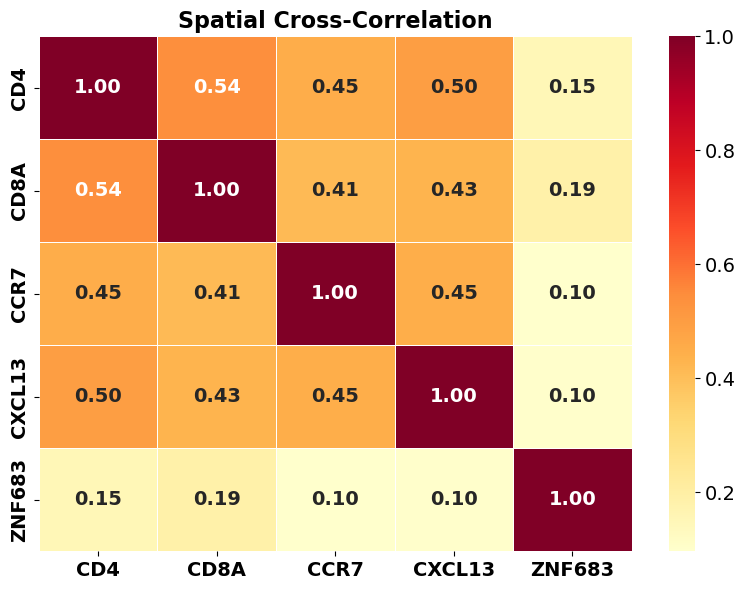

In [9]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

genes = ["CD4", "CD8A", "CCR7", "CXCL13", "ZNF683"]
results = []
norm = dict()

# 1. Collect data into a list
for gene1 in genes:
    row = []
    expr_a = np.asarray(adata_sample.X[:, adata_sample.var_names.get_loc(gene1)].todense()).flatten()
    for gene2 in genes:
        expr_b = np.asarray(adata_sample.X[:, adata_sample.var_names.get_loc(gene2)].todense()).flatten()
        if gene2 not in norm.keys():
            norm[gene2] = (expr_b @ W @ expr_b)**0.5
        
        # Compute normalized spatial weighted correlation
        # The resulting scores lie in [0, 1]
        score = (expr_a @ W @ expr_b) / (norm[gene1] * norm[gene2])
        row.append(score)
    results.append(row)

# 2. Convert to DataFrame and plot heatmap
df = pd.DataFrame(results, index=genes, columns=genes)
plt.figure(figsize=(8, 6))

ax = sns.heatmap(df, annot=True, fmt=".2f", cmap="YlOrRd", linewidths=0.5, annot_kws={"size": 14, "weight": "bold"})

# Set title
ax.set_title("Spatial Cross-Correlation", fontsize=16, fontweight='bold')

# 3. Adjust font size and weight of gene labels on both axes
ax.tick_params(axis='both', labelsize=14) 

# Make all x-axis and y-axis gene labels bold
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

# Get colorbar object
cbar = ax.collections[0].colorbar

# Set font size of colorbar tick labels
cbar.ax.tick_params(labelsize=14) 


plt.tight_layout()
plt.show()

In [ ]:
values = tp.X.toarray()
mean_vector = np.mean(values/(np.sum((W @ values)*values,axis=0)**0.5+1e-12),axis=1)
mean_vector @ W @ mean_vector
# 数据基因间平均空间相关性是0.09936553468785489